# Dependencies

In [1]:
pacman::p_load( ggpubr,lsmeans,
    igraph, graphlayouts, 
    dplyr, ggplot2, 
    GUniFrac, ggsignif,
    iNEXT, ggrepel, tidyr
)

# Functions

In [2]:
colpal <- c("Vincristine" = "#E41A1C", 
           "Methotrexate" = "#377EB8",
           "Cyclophosphamide" = "#4DAF4A",
           "Vincristine/Methotrexate" = "#984EA3",
           "Vincristine/Cyclophosphamide" = "#fa9734",
           "Vincristine/Methotrexate/Cyclophosphamide" = "#f781bf",
           "No therapy" = "grey",
           "Others" = "#6c6c6c")


In [3]:
source("~/git/ped_CapTCRseq/R/functions/ggplot2_theme.R")
source("~/git/ped_CapTCRseq/R/functions/color_schemes.R")
source("~/git/ped_CapTCRseq/R/functions/Misc_functions.R")

In [4]:
baseraincloud_plot.fx <- function(mydf, yvar, xvar, fillvar, colpal, binw, pointsize) {
    p0 <- ggplot(data = mydf, aes(x = eval(parse(text = xvar)), y = eval(parse(text = yvar)), fill = eval(parse(text = fillvar)))) +
        ggdist::stat_dist_halfeye(adjust = 0.5, .width = 0, justification = -0.1, point_color = NA, width = 0.7) +
        geom_boxplot(width = 0.1, outlier.shape = NA, alpha = 0.5) +
        ggdist::stat_dots(side = "left", justification = 1.1) +
        scale_fill_manual(values = colpal) +
        myaxis +
        myplot +
        theme(legend.position = "none") +
        #scale_y_continuous(limits = c(0, 110), breaks = c(0, 25, 50, 75, 100)) +
        labs(x = "", y = gsub("`", "", yvar))
    return(p0)
}


In [5]:
set.seed(111)
baseplot.fx <- function(mydf, x, y, fill, clr, colpal) {
    p1 <- ggplot(mydf, aes(x = factor(eval(parse(text = x))), y = eval(parse(text = y)), color = eval(parse(text = clr)), fill = eval(parse(text = fill)))) +
        geom_jitter(width = 0.1, height = 0.1, alpha = 0.2) +
        geom_boxplot(outlier.shape = NA, alpha = 0.1) +
        # geom_smooth(method = "loess", se = TRUE, aes(group = 1), color = "black", fill = "grey") +
        myplot +
        myaxis +
        scale_color_manual(values = colpal) +
        scale_fill_manual(values = colpal) +
        theme(legend.position = "none") +
        labs(x = x, y = gsub("`", "", y))
    return(p1)
}


# Paths

In [6]:
datapath <- "~/OneDrive - UHN/Documents/INTERCEPT/Data/"
plotpath <- "~/OneDrive - UHN/Documents/INTERCEPT/Plots/"
manifestpath <- "~/OneDrive - UHN/Documents/INTERCEPT/Manifests/"
gitpath <- "~/git/ped_CapTCRseq/"

In [7]:
h4hpath <- "~/Desktop/H4H/INTERCEPT/analysis/GLIPH/run_gliph/"

# Main

In [8]:
datapath <- "~/git/ped_CapTCRseq/data/"
meta_div <- readr::read_rds(paste0(datapath, "metadata.rds"))

In [9]:
soc_good <- readr::read_rds(paste0(datapath,"soc_good_with_baseregimen.rds"))
soc_good_long <- soc_good %>%
  pivot_longer(
    cols = starts_with("base_regimen_"),
    names_to = "cycle",
    values_to = "regimen",
    names_prefix = "base_regimen_"
  ) %>%
  select(Patient, cycle, regimen)

head(soc_good_long)
# Join soc_good_long to meta_div
# First, create a mapping between cycle formats (X05 -> cycle5)
meta_div$cycle_mapped <- paste0("cycle", gsub("X0?", "", meta_div$cycle))

# Join the datasets
meta_div <- meta_div %>%
  left_join(soc_good_long, by = c("Patient" = "Patient", "cycle_mapped" = "cycle"))

# Clean up the temporary column
 meta_div$cycle_mapped <- NULL

# (meta_div[ meta_div$Patient == "CHP_407",])

Patient,cycle,regimen
<chr>,<chr>,<fct>
CHP_319,cycle1,Vincristine
CHP_319,cycle2,Vincristine/Cyclophosphamide
CHP_319,cycle3,Vincristine/Methotrexate
CHP_319,cycle4,Vincristine/Cyclophosphamide
CHP_319,cycle5,Vincristine/Methotrexate
CHP_323,cycle1,Vincristine


In [10]:
# Create exposed_regimen column, for each patient, if cycle is X01, then it is baseline, otherwise it is the previous cycle's regimen
## Use the soc_good dataframe to get the regimen for the previous cycle
## First, create a mapping between cycle formats (X05 -> cycle5)
## be explicit, eg get regimen of X04 for exponsed_regimen of X05
# Create exposed_regimen column
meta_div$exposed_regimen <- NA

# For each sample, determine the exposed regimen
for (i in 1:nrow(meta_div)) {
  current_patient <- meta_div$Patient[i]
  current_cycle <- meta_div$cycle[i]
  
  # If it's X01 (first cycle), exposed_regimen is NA (baseline)
  if (current_cycle == "X01") {
    meta_div$exposed_regimen[i] <- "baseline"
  } else {
    # Extract cycle number and get previous cycle
    cycle_num <- as.numeric(gsub("X0?", "", current_cycle))
    prev_cycle_num <- cycle_num - 1
    
    # Format previous cycle (e.g., 4 -> "cycle4")
    prev_cycle_col <- paste0("cycle", prev_cycle_num)
    
    # Get the base regimen for the previous cycle from soc_good
    prev_regimen <- as.character(soc_good[soc_good$Patient == current_patient, paste0("base_regimen_", prev_cycle_col), drop = T])
    
    if (length(prev_regimen) > 0 && !is.na(prev_regimen)) {
      meta_div$exposed_regimen[i] <- prev_regimen
    }
  }
}



In [11]:
#remove those samples that we did not have the TCRseq data for
meta_div <- meta_div[!is.na(meta_div$TRB),]

In [12]:
meta_div[ grepl("336", meta_div$file),]

,sample_id,Patient,cycle,FOLD,ATC,Age,Disease_type,TE_fold,CD3,EM,⋯,SE_Simpson,basename,file,sampletype,Group,log10shann,sample_id_sampletype,assay,regimen,exposed_regimen
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<int>,⋯,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<fct>,<chr>
215,CHP_336_03,CHP_336,X03,0,0,11,ALL,0,NA,NA,⋯,0.04845674,CHP_336-03_cfDNA,batch10_cfDNA_13Jul2020/mixcr/clones/CLONES_TRBCHP_336-03_cfDNA.txt,cfDNA,CHP,0.6656184,CHP_336_03_cfDNA,capTCR-seq,Vincristine/Methotrexate,Vincristine/Cyclophosphamide
216,CHP_336_04,CHP_336,X04,0,0,11,ALL,0,NA,NA,⋯,0.03890623,CHP_336-04_cfDNA,batch10_cfDNA_13Jul2020/mixcr/clones/CLONES_TRBCHP_336-04_cfDNA.txt,cfDNA,CHP,0.6986264,CHP_336_04_cfDNA,capTCR-seq,Vincristine/Cyclophosphamide,Vincristine/Methotrexate
217,CHP_336_05,CHP_336,X05,0,0,11,ALL,0,NA,NA,⋯,0.05794069,CHP_336-05_cfDNA,batch10_cfDNA_13Jul2020/mixcr/clones/CLONES_TRBCHP_336-05_cfDNA.txt,cfDNA,CHP,0.7945001,CHP_336_05_cfDNA,capTCR-seq,Vincristine/Methotrexate,Vincristine/Cyclophosphamide


In [13]:
table(meta_div$sampletype)


cfDNA  PBMC 
  253   199 

In [14]:
length(table(meta_div$Patient[ meta_div$sampletype == "PBMC"]))

[1] 86

In [15]:
sum(meta_div$TRB)

[1] 53316

# Fisher score vs delta per regimen

In [16]:
samples_tcr <- readr::read_rds(file = paste0(datapath, "int_samples_gliph_tigerdb_annot_stat.rds"))
gliphdf <- readr::read_rds( file = paste0(datapath, "gliph_tigerdb_annot_stat.rds"))

In [19]:
gliph_out <- readr::read_rds(file = paste0(datapath, "int_gliph_tigerdb_cleaned.rds"))

In [21]:
chp_gliph <- gliph_out[ grepl("CHP", gliph_out$Sample), ]
# chp_gliph <- chp_gliph[!grepl("Normal", chp_gliph$subject),]

In [22]:
chp_gliph_pbmc <- chp_gliph[grepl("PBMC", chp_gliph$Sample),]

In [23]:
chp_gliph_pbmc$Patient <- meta_div$Patient[match(chp_gliph_pbmc$Sample, meta_div$basename)]
chp_gliph_pbmc$cycle <- meta_div$cycle[match(chp_gliph_pbmc$Sample, meta_div$basename)]
chp_gliph_pbmc$sampletype <- meta_div$sampletype[match(chp_gliph_pbmc$Sample, meta_div$basename)]
chp_gliph_pbmc$cancergroup <- meta_div$cancergroup[match(chp_gliph_pbmc$Sample, meta_div$basename)]
chp_gliph_pbmc$regimen <- meta_div$regimen[match(chp_gliph_pbmc$Sample, meta_div$basename)]
chp_gliph_pbmc$exposed_regimen <- meta_div$exposed_regimen[match(chp_gliph_pbmc$Sample, meta_div$basename)]

In [24]:
# get patients with more than one pair of consecutive timepoiints
mytab <- table(chp_gliph_pbmc$Patient, chp_gliph_pbmc$cycle)
# Find patients with at least one pair of consecutive timepoints (e.g., X01-X02, X02-X03, etc)
consecutive_matrix <- mytab > 0
# Only keep rows with at least one pair of adjacent TRUE values
consecutive_matrix <- consecutive_matrix[apply(consecutive_matrix, 1, function(x) any(x[-length(x)] & x[-1])), , drop = FALSE]

baseline_patients <- rownames(consecutive_matrix)

In [26]:
head(consecutive_matrix)

,X01,X02,X03,X04,X05
CHP_328,FALSE,FALSE,FALSE,TRUE,TRUE
CHP_331,FALSE,FALSE,FALSE,TRUE,TRUE
CHP_338,FALSE,FALSE,TRUE,TRUE,TRUE
CHP_340,FALSE,FALSE,TRUE,TRUE,TRUE
CHP_343,FALSE,TRUE,TRUE,TRUE,TRUE
CHP_344,FALSE,TRUE,FALSE,TRUE,TRUE


In [25]:
length(baseline_patients)

[1] 48

In [27]:
df1 <- chp_gliph_pbmc[chp_gliph_pbmc$Patient %in% baseline_patients, ]

In [28]:
table(df1$cycle)


  X01   X02   X03   X04   X05 
 6072 11932  9264  4794  5061 

In [33]:
# separate pre and post
df1_pre <- df1[ df1$cycle == "X01",]
df1_x02 <- df1[ df1$cycle == "X02",]
df1_x03 <- df1[ df1$cycle == "X03",]
df1_x04 <- df1[ df1$cycle == "X04",]
df1_x05 <- df1[ df1$cycle == "X05",]

In [34]:
dim(df1_pre)

[1] 6072   25

In [35]:
# group by samples and patterns, avergae the frequencies, if there is > 1 CDR3s in a pattern. do it for all cycles
df1_pre <- df1_pre %>%
  group_by(Sample, pattern) %>%
  summarise(MeanFreq = mean(Freq), .groups = 'drop') %>%
  ungroup()
df1_x02 <- df1_x02 %>%  
  group_by(Sample, pattern) %>%
  summarise(MeanFreq = mean(Freq), .groups = 'drop') %>%
  ungroup()
df1_x03 <- df1_x03 %>%
  group_by(Sample, pattern) %>%
  summarise(MeanFreq = mean(Freq), .groups = 'drop') %>%
  ungroup()
df1_x04 <- df1_x04 %>%
  group_by(Sample, pattern) %>%
  summarise(MeanFreq = mean(Freq), .groups = 'drop') %>%
  ungroup()
df1_x05 <- df1_x05 %>%
  group_by(Sample, pattern) %>%
  summarise(MeanFreq = mean(Freq), .groups = 'drop') %>%  
  ungroup()

In [36]:
head(df1_pre)

Sample,pattern,MeanFreq
<chr>,<chr>,<dbl>
CHP-369-01-PBMC-DNA,%AGTENTE,130
CHP-369-01-PBMC-DNA,%AGTGGYE,482
CHP-369-01-PBMC-DNA,%ESKGNQP,201
CHP-369-01-PBMC-DNA,%ETGENTE,23
CHP-369-01-PBMC-DNA,%FRDRGVRE,1212
CHP-369-01-PBMC-DNA,%FVTGE,584


In [37]:
# df1_pre$Regimen <- meta_div$regimen[match(df1_pre$Sample, meta_div$basename)]
# df1_x02$Regimen <- meta_div$regimen[match(df1_x02$Sample, meta_div$basename)]
# df1_x03$Regimen <- meta_div$regimen[match(df1_x03$Sample, meta_div$basename)]
# df1_x04$Regimen <- meta_div$regimen[match(df1_x04$Sample, meta_div$basename)]
# df1_x05$Regimen <- meta_div$regimen[match(df1_x05$Sample, meta_div$basename)]

df1_pre$exposed_regimen <- meta_div$exposed_regimen[match(df1_pre$Sample, meta_div$basename)]
df1_x02$exposed_regimen <- meta_div$exposed_regimen[match(df1_x02$Sample, meta_div$basename)]
df1_x03$exposed_regimen <- meta_div$exposed_regimen[match(df1_x03$Sample, meta_div$basename)]
df1_x04$exposed_regimen <- meta_div$exposed_regimen[match(df1_x04$Sample, meta_div$basename)]
df1_x05$exposed_regimen <- meta_div$exposed_regimen[match(df1_x05$Sample, meta_div$basename)]

df1_pre$cancergroup <- meta_div$cancergroup[match(df1_pre$Sample, meta_div$basename)]
df1_x02$cancergroup <- meta_div$cancergroup[match(df1_x02$Sample, meta_div$basename)]
df1_x03$cancergroup <- meta_div$cancergroup[match(df1_x03$Sample, meta_div$basename)]
df1_x04$cancergroup <- meta_div$cancergroup[match(df1_x04$Sample, meta_div$basename)]
df1_x05$cancergroup <- meta_div$cancergroup[match(df1_x05$Sample, meta_div$basename)]


In [38]:
df1_pre$Disease_type <- meta_div$Disease_type[match(df1_pre$Sample, meta_div$basename)]
df1_x02$Disease_type <- meta_div$Disease_type[match(df1_x02$Sample, meta_div$basename)]
df1_x03$Disease_type <- meta_div$Disease_type[match(df1_x03$Sample, meta_div$basename)]
df1_x04$Disease_type <- meta_div$Disease_type[match(df1_x04$Sample, meta_div$basename)]
df1_x05$Disease_type <- meta_div$Disease_type[match(df1_x05$Sample, meta_div$basename)]

df1_pre$Patient <- meta_div$Patient[match(df1_pre$Sample, meta_div$basename)]
df1_x02$Patient <- meta_div$Patient[match(df1_x02$Sample, meta_div$basename)]
df1_x03$Patient <- meta_div$Patient[match(df1_x03$Sample, meta_div$basename)]
df1_x04$Patient <- meta_div$Patient[match(df1_x04$Sample, meta_div$basename)]
df1_x05$Patient <- meta_div$Patient[match(df1_x05$Sample, meta_div$basename)]


In [39]:
# Requirements
library(dplyr)
library(tidyr)
library(tibble)

# 1) Standardize the five dfs (accept either Freq or MeanFreq) and bind with explicit cycle labels
standardize_cycle_df <- function(df, cycle_label) {
  has_meanfreq <- "MeanFreq" %in% colnames(df)
  out <-  df %>% select(Sample, pattern, Patient,MeanFreq, exposed_regimen)
  out$cycle <- cycle_label
  out
}

df_list <- list(
  X01 = df1_pre,
  X02 = df1_x02,
  X03 = df1_x03,
  X04 = df1_x04,
  X05 = df1_x05
)

df_all <- do.call(rbind, lapply(names(df_list), function(nm) standardize_cycle_df(df_list[[nm]], nm)))



Attaching package: ‘tibble’


The following object is masked from ‘package:igraph’:

    as_data_frame




In [41]:
head(df_all)

Sample,pattern,Patient,MeanFreq,exposed_regimen,cycle
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
CHP-369-01-PBMC-DNA,%AGTENTE,CHP_369,130,baseline,X01
CHP-369-01-PBMC-DNA,%AGTGGYE,CHP_369,482,baseline,X01
CHP-369-01-PBMC-DNA,%ESKGNQP,CHP_369,201,baseline,X01
CHP-369-01-PBMC-DNA,%ETGENTE,CHP_369,23,baseline,X01
CHP-369-01-PBMC-DNA,%FRDRGVRE,CHP_369,1212,baseline,X01
CHP-369-01-PBMC-DNA,%FVTGE,CHP_369,584,baseline,X01


In [43]:
sample_pat_map <- df_all[, c("Sample", "Patient","cycle", "exposed_regimen")]
sample_pat_map <- unique(sample_pat_map)

In [35]:
# # 2) Add Patient and Regimen for each Sample

# spm <- sample_pat_map[, c("Sample", "Patient", "regimen")]
# df_all <- df_all %>% left_join(spm, by = "Sample")

In [44]:
to_num <- function(x) as.integer(gsub("\\D", "", x))
df_pc2 <- df_all %>% mutate(cycle_num = to_num(cycle))

In [53]:
length(unique(df_pc2$pattern))

[1] 7024

In [73]:
from <- df_pc2 %>%
  transmute(
    Patient, pattern,
    cycle_from = cycle,
    cycle_num_from = cycle_num,
    MeanFreq_from = MeanFreq,
    next_cycle_num = cycle_num + 1L
  )

to <- df_pc2 %>%
  transmute(
    Patient, pattern,
    cycle_to = cycle,
    cycle_num_to = cycle_num,
    MeanFreq_to = MeanFreq
  )

# Safe inner join: (Patient, pattern, next_cycle_num) -> (Patient, pattern, cycle_num_to)
delta_long <- from %>%
  inner_join(to, by = c("Patient", "pattern", "next_cycle_num" = "cycle_num_to")) %>%
  transmute(
    Patient, pattern,
    cycle_from, cycle_to, next_cycle_num,
    MeanFreq_from, MeanFreq_to,
    Delta = MeanFreq_to - MeanFreq_from
  )

In [74]:
length(unique(delta_long$Patient))

[1] 40

In [75]:
length(unique(delta_long$pattern))

[1] 189

In [76]:
delta_long[ delta_long$Patient == "CHP_405" & delta_long$pattern == "VLR",]

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
CHP_405,VLR,X01,X02,2,2.833333,9.0,6.166667
CHP_405,VLR,X02,X03,3,9.000000,10.0,1.000000
CHP_405,VLR,X03,X04,4,10.000000,9.2,-0.800000
CHP_405,VLR,X04,X05,5,9.200000,59.0,49.800000


In [77]:
library(dplyr)

# fisher per pattern (choose best/lowest fisher if duplicated)
pattern_fisher <- df1 %>%
    distinct(pattern, Fisher_score) %>%
    group_by(pattern) %>%
    summarise(fisher = suppressWarnings(min(Fisher_score, na.rm = TRUE)), .groups = "drop") %>%
    mutate(fisher = ifelse(is.infinite(fisher), NA_real_, fisher))

# regimen per Patient x cycle (for the "to" cycle)
regimen_pc <- sample_pat_map %>%
    select(Patient, cycle, exposed_regimen) %>%
    group_by(Patient, cycle) %>%
    summarise(exposed_regimen = dplyr::first(na.omit(exposed_regimen)), .groups = "drop")

# antigen flags by pattern (gliphdf keyed by `gliph`)
ant_lookup <- gliphdf %>%
    select(gliph, CMV, Influenza, HCV, EBV, HPV, Human, CEF, HSV, TB, SP, MCPyV, YFV) %>%
    rename(Flu = Influenza, HS = Human)

# attach directly to delta_long
delta_long <- delta_long %>%
    left_join(pattern_fisher, by = "pattern") %>%
    left_join(regimen_pc, by = c("Patient", "cycle_to" = "cycle")) %>%
    left_join(ant_lookup, by = c("pattern" = "gliph"))

# (Optional) derive categorical antigen label for plotting shape
viral_cols     <- c("CMV", "Flu", "HCV", "EBV", "HPV", "MCPyV", "HSV", "YFV")
bacterial_cols <- c("TB", "SP")

delta_long$antigen <- "Unknown"
delta_long$antigen[rowSums(delta_long[, viral_cols],     na.rm = TRUE) > 0] <- "Viral"
delta_long$antigen[rowSums(delta_long[, bacterial_cols], na.rm = TRUE) > 0] <- "Bacterial"
delta_long$antigen[delta_long$HS > 0] <- "HomoSapiens"
delta_long$antigen[
    (delta_long$HS > 0) &
    (rowSums(delta_long[, c(viral_cols, bacterial_cols)], na.rm = TRUE) > 0)
] <- "Cross-reactive"

In [78]:
summary(delta_long$Delta)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-465.000  -12.633    0.750    7.237   10.000  772.300 

In [79]:
quantiles <- quantile(delta_long$Delta, c(0.1, 0.9))

In [80]:
min(delta_long$fisher[ delta_long$fisher > 0])

[1] 5.4e-29

In [81]:
delta_long$log10fisher <- -log10(delta_long$fisher + 1e-30)

In [82]:
head(meta_div[ meta_div$Patient == "CHP_369",])

,sample_id,Patient,cycle,FOLD,ATC,Age,Disease_type,TE_fold,CD3,EM,⋯,SE_Simpson,basename,file,sampletype,Group,log10shann,sample_id_sampletype,assay,regimen,exposed_regimen
,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<int>,⋯,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<fct>,<chr>
94,CHP_369_01,CHP_369,X01,5.1,544.44,0.1,AML,5.1,1591,4,⋯,0.6934305,CHP-369-01-PBMC-DNA,remaining_batch_4_28June2021/mixcr/clones/CLONES_TRBCHP-369-01-PBMC-DNA.txt,PBMC,CHP,2.588846,CHP_369_01_PBMC,Flow cytometry & capTCR-seq,Others,baseline
95,CHP_369_02,CHP_369,X02,0.0,0.00,0.1,AML,0.0,NA,NA,⋯,3.6862007,CHP_369-02-PBMC-DNA,batch8_14Jan2020/mixcr/clones/CLONES_TRBCHP_369-02-PBMC-DNA.txt,PBMC,CHP,2.210669,CHP_369_02_PBMC,capTCR-seq,Others,Others
308,CHP_369_02,CHP_369,X02,0.0,0.00,0.1,AML,0.0,NA,NA,⋯,0.1092570,CHP_369-02_cfDNA,batch10_cfDNA_13Jul2020/mixcr/clones/CLONES_TRBCHP_369-02_cfDNA.txt,cfDNA,CHP,1.353341,CHP_369_02_cfDNA,capTCR-seq,Others,Others


In [83]:
pattern_patient_count <- delta_long %>%
  dplyr::distinct(Patient, pattern) %>%
  dplyr::count(pattern, name = "n_patients_with_pattern")

# Attach to delta_long
delta_long <- delta_long %>%
  dplyr::left_join(pattern_patient_count, by = "pattern")


In [84]:
head(pattern_patient_count)

pattern,n_patients_with_pattern
<chr>,<int>
%DSNQP,1
%GGSSYE,1
%LDRNTE,1
%LGQNTE,1
%RGGSYE,1
%RLNTE,1


In [71]:
# length(unique(delta_long[ delta_long$pattern == "AEVS",]$Patient))

In [85]:
head(delta_long)

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,⋯,HS,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>
CHP_369,AEV,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,1,0,Viral,30,29
CHP_369,AEVS,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Unknown,30,29
CHP_369,AGW,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,3,0,0,0,0,0,0,HomoSapiens,30,30
CHP_369,AGWA,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Unknown,30,29
CHP_369,APE,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Viral,30,30
CHP_369,APES,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Unknown,30,29


In [86]:
delta_long$exposed_regimen <- factor(delta_long$exposed_regimen, levels = c("No therapy", setdiff(names(colpal), "No therapy")))

In [90]:
pt <- unique(delta_long$pattern[ delta_long$fisher < 0.0001]) # sig patterns
length(pt)

[1] 87

In [93]:
# number of significant patterns that occur in more than one patient
delta_long %>%
  dplyr::filter(fisher < 0.0001) %>%
  dplyr::distinct(pattern, Patient) %>%
  dplyr::count(pattern, name = "n_patients") %>%
  dplyr::filter(n_patients > 1) %>%
  nrow()

[1] 71

In [94]:
sig_multi_patterns <- delta_long %>%
  dplyr::filter(fisher < 0.0001) %>%
  dplyr::distinct(pattern, Patient) %>%
  dplyr::count(pattern, name = "n_patients") %>%
  dplyr::filter(n_patients > 1) %>%
  dplyr::pull(pattern)

delta_long_sig <- delta_long %>%
  dplyr::filter(pattern %in% sig_multi_patterns)

In [96]:
summary(delta_long_sig$Delta)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-316.333  -12.333    0.750    8.015   10.000  772.300 

In [101]:
head(delta_long[ order(delta_long$Delta,decreasing = TRUE), ])

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,⋯,HS,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>
CHP_405,EVS,X04,X05,5,9.2,781.5,772.3,0.00,Others,⋯,3,0,0,0,0,0,0,HomoSapiens,30.0000000,29
CHP_413,AGW,X01,X02,2,18.0,759.0,741.0,0.00,Others,⋯,3,0,0,0,0,0,0,HomoSapiens,30.0000000,30
CHP_414,S%DRGGE,X02,X03,3,36.0,541.0,505.0,0.20,Vincristine,⋯,0,0,0,0,0,0,0,Unknown,0.6989700,1
CHP_412,SLS%NE,X01,X02,2,18.0,484.0,466.0,0.16,Vincristine/Cyclophosphamide,⋯,1,0,0,0,0,0,0,HomoSapiens,0.7958800,1
CHP_405,PTL,X04,X05,5,9.2,471.0,461.8,0.00,Others,⋯,2,0,0,0,0,0,0,Cross-reactive,30.0000000,32
CHP_405,SL%RDYE,X04,X05,5,28.0,457.0,429.0,0.31,Others,⋯,0,0,0,0,0,0,0,Unknown,0.5086383,1


In [102]:
tail(delta_long[ order(delta_long$Delta,decreasing = TRUE), ])

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,⋯,HS,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>
CHP_381,SL%GATE,X01,X02,2,256.0000,8.00000,-248.0000,1.5e-02,Vincristine/Cyclophosphamide,⋯,0,0,0,0,0,0,0,Unknown,1.8239087,1
CHP_381,TVL,X01,X02,2,294.0000,12.22222,-281.7778,0.0e+00,Vincristine/Cyclophosphamide,⋯,3,0,0,0,0,0,0,Cross-reactive,30.0000000,32
CHP_381,QAVS,X01,X02,2,316.0000,1.00000,-315.0000,5.8e-24,Vincristine/Cyclophosphamide,⋯,0,0,0,0,0,0,0,Viral,23.2365719,1
CHP_328,TVL,X04,X05,5,403.6667,87.33333,-316.3333,0.0e+00,Vincristine/Cyclophosphamide,⋯,3,0,0,0,0,0,0,Cross-reactive,30.0000000,32
CHP_399,SQ%GNTE,X02,X03,3,345.5000,6.00000,-339.5000,2.5e-03,Vincristine/Cyclophosphamide,⋯,0,0,0,0,0,0,0,Unknown,2.6020600,2
CHP_365,S%RGNTE,X01,X02,2,479.0000,14.00000,-465.0000,4.1e-01,Vincristine,⋯,0,0,0,0,0,0,0,Unknown,0.3872161,1


In [99]:
chp405patterns <- delta_long_sig$pattern[ delta_long_sig$Patient == "CHP_405"]

In [100]:
temp <- gliph_out[ gliph_out$pattern %in% "PTL",]
gliph_405 <- gliph_out[ gliph_out$pattern %in% chp405patterns,]
humanpatternsfor405 <- gliph_405[grepl("Human", gliph_405$subject),]
humanpatternsfor405[ grepl("VVLSWAPPV", humanpatternsfor405$Sample),]
unique(humanpatternsfor405$Sample)

index,pattern,Fisher_score,number_subject,number_unique_cdr3,final_score,hla_score,vb_score,expansion_score,length_score,cluster_size_score,type,TcRb,V,J,TcRa,Sample,Freq,subject
<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
9585,EVS,0.98,39,49,2.1e-07,1,0.99,0.2,0.048,2.2e-05,motif-EVS,CASSEVSVLYEQYF,TRBV2,NA,NA,Human:A*02__FNDC3B__p.L3M__TRUE__VVLSWAPPV,1,Human


[1] "Human:A*02:01__ATP8B2__SF3B1-p.R625C-Induced-AltSplicing__NA__AALPILFQV"           
 [2] "Human:A*02:01__MAPK8IP2__SF3B1-p.R625S-Induced-AltSplicing__NA__RLPGVLPRA"         
 [3] "Human:A*02:01__PORCN__p.H346Y__FALSE__LLHGFSFYL"                                   
 [4] "Human:A*02:01__MAPK8IP2__SF3B1-p.R625C-Induced-AltSplicing__NA__RLPGVLPRA"         
 [5] "Human:NA__SNRPB__p.S56F__FALSE__CDCDEFRKIKPKNFKQAERE"                              
 [6] "Human:MR1__5-OP-RU__WT__TRUE__NonConventional"                                     
 [7] "Human:NA__MAA__NA__NA__NA"                                                         
 [8] "Human:B*15:01__TYR__WT__TRUE__RLPSSADVEF"                                          
 [9] "Human:DRB1__KIF4B__p.R744K__NA__GIAARVKNWL"                                        
[10] "Human:A*02:01__MLANA__WT__TRUE__AAGIGILTV"                                         
[11] "Human:A*02__PGM5__p.H469Y__FALSE__AVGSYVYSV"                                       
[12] "Human:A*02:01__MLANA-orBST2-orIMP2__WT__TRUE__EAAGIGILTV-orLLLGIGILVL-orNLSALGIFST"
[13] "Human:NA__H3F3B__p.A48T__NA__VKKPHRYRPGTVTLREIRRYQKSTE"                            
[14] "Human:DRB5*01:01__KRAS__p.G12V__NA__MTEYKLVVVGAVGVGKSALT"                          
[15] "Human:A*02__PIGN__p.P824H__FALSE__FLTVFSHFM"                                       
[16] "Human:A*24:02__PPM1F__p.C259Y__NA__VYALIAGATL"                                     
[17] "Human:A*02__GANAB__p.S5F__FALSE__ALYGFVPVL"                                        
[18] "Human:A*02:01__EXOC8__p.Q656P__NA__IILVAVPHV"                                      
[19] "Human:A*02__FNDC3B__p.L3M__TRUE__VVLSWAPPV"                                        
[20] "Human:A*02__HTR1F__WT__TRUE__VMPFSIVYIV"                                           
[21] "Human:NA__HHAT__p.R132P__FALSE__NA"

In [103]:
tab <- as.data.frame.matrix(table(delta_long_sig$antigen, delta_long_sig$pattern))
(rowSums(tab > 0))

Bacterial Cross-reactive    HomoSapiens        Unknown          Viral 
             1              7             13             41              9

In [105]:
41/71

[1] 0.5774648

In [106]:
head(delta_long)

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,⋯,HS,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>
CHP_369,AEV,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,1,0,Viral,30,29
CHP_369,AEVS,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Unknown,30,29
CHP_369,AGW,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,3,0,0,0,0,0,0,HomoSapiens,30,30
CHP_369,AGWA,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Unknown,30,29
CHP_369,APE,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Viral,30,30
CHP_369,APES,X01,X02,2,30.44444,9.5,-20.94444,0,Others,⋯,0,0,0,0,0,0,0,Unknown,30,29


In [ ]:
# saveRDS(delta_long, file = "delta_consecutive_samples_patterns.rds")

In [53]:
p4 <- ggplot() +
    geom_point(data = delta_long, aes(x = Delta, y = -log10(fisher + 1e-25), 
    color = exposed_regimen, shape = antigen, size = n_patients_with_pattern),
    alpha = 0.8) +
    myplot +
    myaxis +
    # geom_hline(yintercept = -log10(0.0001), linetype = 5) +
    geom_vline(xintercept = c(quantiles[1], quantiles[2]), linetype = 3) +
    theme(axis.text.x = element_text(angle = 0, hjust = 0.5), legend.title = element_text(size = 10)) +
    labs(y = "-log10(Fisher score)", x = "TCR specificity group clonal change \n[post-therapy - pre-therapy]") +
    guides(color = guide_legend(title = "exposed_regimen"), 
    shape = guide_legend(title = "Antigen"), 
    size = guide_legend(title = "Unique CDR3s (count)")) +
    scale_color_manual(values = colpal) + scale_size_continuous(range = c(3, 6))

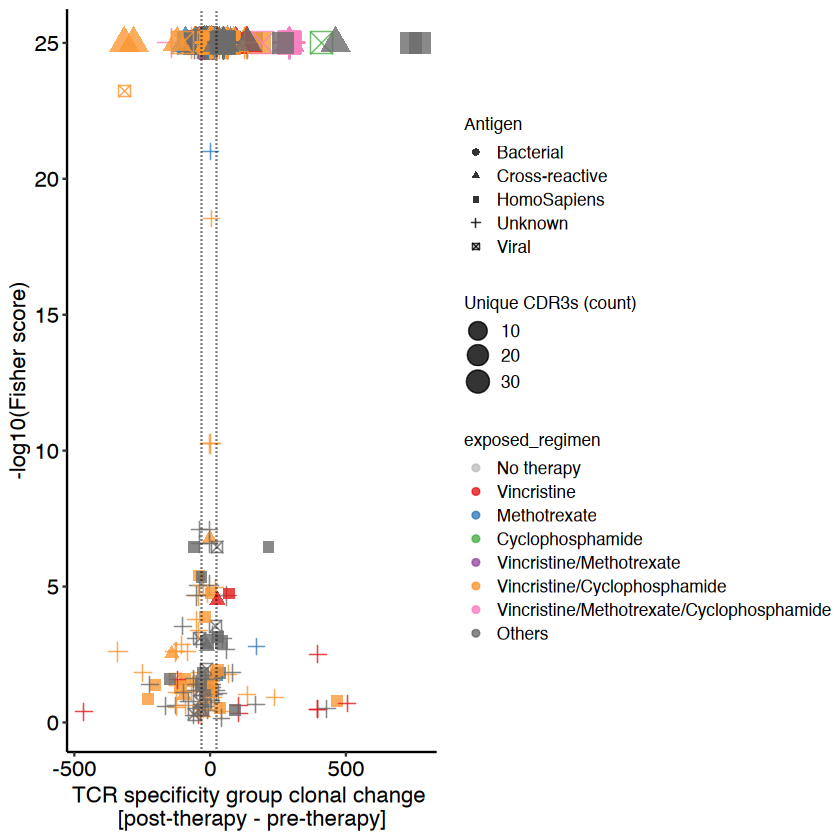

In [54]:
p4

In [ ]:
pdf(paste0(plotpath, "5A.pdf"), width = 10, height = 7)
cowplot::plot_grid(p4, labels = "A")
dev.off()

In [56]:
summary(delta_long$fisher)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.00000 0.00000 0.00000 0.00514 0.00000 0.70000 

In [493]:
head(delta_long)

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,...,HS,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>
CHP_369,AEV,X01,X02,2,30.44444,9.5,-20.94444,0,Others,...,0,0,0,0,0,1,0,Viral,30,29
CHP_369,AEVS,X01,X02,2,30.44444,9.5,-20.94444,0,Others,...,0,0,0,0,0,0,0,Unknown,30,29
CHP_369,AGW,X01,X02,2,30.44444,9.5,-20.94444,0,Others,...,3,0,0,0,0,0,0,HomoSapiens,30,30
CHP_369,AGWA,X01,X02,2,30.44444,9.5,-20.94444,0,Others,...,0,0,0,0,0,0,0,Unknown,30,29
CHP_369,APE,X01,X02,2,30.44444,9.5,-20.94444,0,Others,...,0,0,0,0,0,0,0,Viral,30,30
CHP_369,APES,X01,X02,2,30.44444,9.5,-20.94444,0,Others,...,0,0,0,0,0,0,0,Unknown,30,29


In [57]:
top_patterns <- delta_long$pattern[ delta_long$fisher < 0.0001 & delta_long$n_patients_with_pattern > 1]

In [58]:
# Build ordered rows from top_patterns and plot
top_df <- delta_long %>%
    dplyr::filter(pattern %in% top_patterns) %>%
    dplyr::arrange(dplyr::desc(Delta)) %>%
    dplyr::mutate(row = dplyr::row_number())

In [59]:
# Count number of unique antigens among unique patterns in top_df
top_unique_patterns <- top_df %>% dplyr::distinct(pattern, .keep_all = TRUE)
num_unique_antigens <- length(unique(top_unique_patterns$antigen))
print(num_unique_antigens)


[1] 5


In [60]:
length(unique(top_df$pattern))

[1] 71

In [61]:
length(unique(top_df$Patient))
# summary(top_df$n_patients_with_pattern)

[1] 39

In [62]:
summary(top_df$n_patients_with_pattern)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   2.00   29.00   29.00   29.15   29.00   33.00 

In [63]:
summary(top_df$Delta)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-316.333  -12.333    0.750    8.015   10.000  772.300 

In [64]:
tab <- as.data.frame.matrix(table(top_df$antigen, top_df$pattern))
(rowSums(tab > 0))
tab

Bacterial Cross-reactive    HomoSapiens        Unknown          Viral 
             1              7             13             41              9

,AEV,AEVS,AGW,AGWA,APE,APES,AVGA,AVL,AVLR,CP,⋯,TLRG,TVL,TVLG,VGAP,VLGK,VLR,VLRG,VSSC,WAE,WAEV
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
Bacterial,0,0,0,0,0,0,39,0,0,0,⋯,0,0,0,0,0,0,0,0,0,0
Cross-reactive,0,0,0,0,0,0,0,40,0,0,⋯,0,41,0,0,0,0,0,0,37,0
HomoSapiens,0,0,39,0,0,0,0,0,0,39,⋯,0,0,35,0,0,37,0,0,0,0
Unknown,0,37,0,37,0,37,0,0,37,0,⋯,0,0,0,37,36,0,37,37,0,37
Viral,37,0,0,0,40,0,0,0,0,0,⋯,38,0,0,0,0,0,0,0,0,0


In [65]:
head(top_df, 5)

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,⋯,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern,row
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<int>
CHP_405,EVS,X04,X05,5,9.20000,781.5,772.3000,0,Others,⋯,0,0,0,0,0,0,HomoSapiens,30,29,1
CHP_413,AGW,X01,X02,2,18.00000,759.0,741.0000,0,Others,⋯,0,0,0,0,0,0,HomoSapiens,30,30,2
CHP_405,PTL,X04,X05,5,9.20000,471.0,461.8000,0,Others,⋯,0,0,0,0,0,0,Cross-reactive,30,32,3
CHP_418,LRGA,X01,X02,2,13.66667,424.0,410.3333,0,Cyclophosphamide,⋯,0,0,0,0,1,0,Viral,30,31,4
CHP_403,EVS,X02,X03,3,3.80000,295.5,291.7000,0,Vincristine/Methotrexate/Cyclophosphamide,⋯,0,0,0,0,0,0,HomoSapiens,30,29,5


In [76]:
head(top_df[ top_df$Patient == "CHP_405",], 5)

Patient,pattern,cycle_from,cycle_to,next_cycle_num,MeanFreq_from,MeanFreq_to,Delta,fisher,exposed_regimen,⋯,CEF,HSV,TB,SP,MCPyV,YFV,antigen,log10fisher,n_patients_with_pattern,row
<chr>,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<int>
CHP_405,EVS,X04,X05,5,9.2,781.5,772.3,0,Others,⋯,0,0,0,0,0,0,HomoSapiens,30,29,1
CHP_405,PTL,X04,X05,5,9.2,471.0,461.8,0,Others,⋯,0,0,0,0,0,0,Cross-reactive,30,32,3
CHP_405,GWA,X04,X05,5,9.2,277.5,268.3,0,Others,⋯,0,0,0,0,0,0,HomoSapiens,30,29,71
CHP_405,WAE,X04,X05,5,9.2,146.5,137.3,0,Others,⋯,0,1,0,0,0,0,Cross-reactive,30,29,75
CHP_405,AEV,X04,X05,5,9.2,59.0,49.8,0,Others,⋯,0,0,0,0,1,0,Viral,30,29,160


In [77]:
soc_good[ soc_good$Patient == "CHP_381",1:15]

Patient ID,Diagnosis,Cycle 1 Type,Cycle 1 Drugs,Cycle 1 Duration (days),Cycle 1 Steroids,Cycle 2 Type,Cycle 2 Drugs,Cycle 2 Duration (days),Cycle 2 Steroids,Cycle 3 Type,Cycle 3 Drugs,Cycle 3 Duration (days),Cycle 3 Steroids,Cycle 4 Type
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
381,Ewings,Induction,"Vincristine, Doxorubicin, Cyclophosphamide",84,no,Consolidation,"Ifosphamide, Etoposide *Cycles alternate between these two regimens (cycle 1 and cycle 2)",154,no,NA,NA,NA,NA,NA


# 4- Fraction of cdr3s with antigen specificity in each sample per regimen

In [85]:
samples_tcr_freq <- readr::read_rds( file = paste0(datapath, "int_samples_gliph_tigerdb_annot_freq_stat.rds"))
gliphdf_freq <- readr::read_rds(file = paste0(datapath, "gliph_tigerdb_annot_freq_stat.rds"))

In [86]:
samples_tcr_freq$sample_id <- rownames(samples_tcr_freq)

In [87]:
samples_tcr_freq$Relapse <- meta_div$Relapse[ match(samples_tcr_freq$sample_id, meta_div$basename) ]
# samples_tcr_freq$Regimen <- meta_div$regimen[ match(samples_tcr_freq$sample_id, meta_div$basename) ]
samples_tcr_freq$exposed_regimen <- meta_div$exposed_regimen[ match(samples_tcr_freq$sample_id, meta_div$basename) ]
# samples_tcr_freq$Regimen <- meta_div[ match(samples_tcr_freq$sample_id, meta_div$basename) ]

In [88]:
sampletype <- "PBMC"

df1 <- samples_tcr_freq[ samples_tcr_freq$sampletype == sampletype,]

In [89]:
colnames(df1)

[1] "CMV"               "EBV"               "HCV"              
 [4] "HSV"               "Influenza"         "Human"            
 [7] "HPV"               "CEF"               "TB"               
[10] "MCPyV"             "SP"                "HTLV1"            
[13] "YFV"               "n_cdr3"            "cdr3_reads"       
[16] "n_gliph"           "n_cdr3ingliph"     "cdr3reads_ingliph"
[19] "Patient"           "cycle"             "sampletype"       
[22] "cancergroup"       "Age"               "sample_id"        
[25] "Relapse"           "exposed_regimen"

In [90]:
# Inputs
target_regimen <- "Vincristine"  # set your regimen of interest

In [91]:
antigens <- c("Human", 'CMV','EBV','HCV','HPV',"HSV",'MCPyV','Influenza', "YFV", "CEF")

library(dplyr)
library(tidyr)
library(ggplot2)
# Create _frac columns if missing (assumes base antigen counts + cdr3_reads)
frac_cols_exist <- all(paste0(antigens, "_frac") %in% names(df1))
if (!frac_cols_exist) {
  for (ag in antigens) {
    col_ag <- ag
    if (!col_ag %in% names(df1)) next
    df1[[paste0(ag, "_frac")]] <- df1[[col_ag]] / df1$cdr3_reads
  }
}


In [92]:
df_reg <- df1 %>%
  filter(exposed_regimen == target_regimen) %>%
  select(Sample = sample_id, Patient, cycle, exposed_regimen, all_of(paste0(antigens, "_frac"))) %>%
  mutate(cycle_num = to_num(cycle))

In [93]:
# Helper to extract numeric cycle index (X01 -> 1, etc.)
to_num <- function(x) as.integer(gsub("\\D", "", x))

# Keep only rows for the target regimen
df_reg <- df1 %>%
  filter(exposed_regimen == target_regimen) %>%
  select(Sample = sample_id, Patient, cycle, exposed_regimen, all_of(paste0(antigens, "_frac"))) %>%
  mutate(cycle_num = to_num(cycle))

# Build within-patient, within-regimen consecutive cycle pairs
from_tbl <- df_reg %>%
  transmute(Patient, exposed_regimen, cycle_from = cycle, cycle_num_from = cycle_num, across(ends_with("_frac"), identity, .names = "from.{.col}"))

to_tbl <- df_reg %>%
  transmute(Patient, exposed_regimen, cycle_to = cycle, cycle_num_to = cycle_num, across(ends_with("_frac"), identity, .names = "to.{.col}"))

pairs <- from_tbl %>%
  inner_join(to_tbl, by = c("Patient","exposed_regimen"), relationship = "many-to-many") %>%  # safe declaration
   filter(cycle_num_to == cycle_num_from + 1L)

In [70]:
head(pairs)

,Patient,exposed_regimen,cycle_from,cycle_num_from,from.Human_frac,from.CMV_frac,from.EBV_frac,from.HCV_frac,from.HPV_frac,from.HSV_frac,...,to.Human_frac,to.CMV_frac,to.EBV_frac,to.HCV_frac,to.HPV_frac,to.HSV_frac,to.MCPyV_frac,to.Influenza_frac,to.YFV_frac,to.CEF_frac
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,...,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,CHP_350,Vincristine,X02,2,0.07987968,0.011029412,0.010360963,0.009358289,0.003676471,0.005013369,...,0.05248360,0.014526710,0.0299906279,0.002811621,0.009372071,0.0000000000,0.016401125,0.0000000000,0.000000000,0
2,CHP_358,Vincristine,X02,2,0.09509044,0.047028424,0.029457364,0.000000000,0.057881137,0.029457364,...,0.04967427,0.012418567,0.0105863192,0.002951954,0.007125407,0.0028501629,0.006209283,0.0029519544,0.000000000,0
3,CHP_360,Vincristine,X02,2,0.05757196,0.013141427,0.014080100,0.001877347,0.001877347,0.001877347,...,0.03643216,0.008165829,0.0062814070,0.003454774,0.004396985,0.0043969849,0.004396985,0.0009422111,0.002512563,0
4,CHP_365,Vincristine,X02,2,0.04894327,0.000000000,0.000000000,0.000000000,0.020022247,0.000000000,...,0.04010462,0.000000000,0.0008718396,0.001743679,0.011333915,0.0000000000,0.000000000,0.0000000000,0.000000000,0
5,CHP_410,Vincristine,X02,2,0.07121439,0.005997001,0.005997001,0.000000000,0.005997001,0.005997001,...,0.06319480,0.031073023,0.0262487640,0.001678003,0.003535792,0.0026068978,0.004944117,0.0000000000,0.005303689,0
6,CHP_414,Vincristine,X02,2,0.05171653,0.009037083,0.008076244,0.007440012,0.003168173,0.002557910,...,0.04108932,0.023051749,0.0062340678,0.002523914,0.003112827,0.0001682609,0.002826784,0.0007992395,0.001640544,0


In [95]:
# Long format: two timepoints (from/to) per pair, per antigen
pairs_long_from <- pairs %>%
  select(Patient, exposed_regimen, cycle_from, cycle_to, starts_with("from.")) %>%
  pivot_longer(starts_with("from."),
               names_to = "var", values_to = "fraction") %>%
  mutate(antigen = sub("^from\\.(.+)_frac$", "\\1", var),
         timepoint = "from",
         cycle = cycle_from) %>%
  select(Patient, exposed_regimen, interval = cycle_to, cycle, antigen, timepoint, fraction)

  pairs_long_to <- pairs %>%
  select(Patient, exposed_regimen, cycle_from, cycle_to, starts_with("to.")) %>%
  pivot_longer(starts_with("to."),
               names_to = "var", values_to = "fraction") %>%
  mutate(antigen = sub("^to\\.(.+)_frac$", "\\1", var),
         timepoint = "to",
         cycle = cycle_to) %>%
  select(Patient, exposed_regimen, interval = cycle_to, cycle, antigen, timepoint, fraction)

pairs_long <- bind_rows(pairs_long_from, pairs_long_to) %>%
  filter(antigen %in% antigens) %>%
  mutate(
    antigen = factor(antigen, levels = antigens),
    # Pair ID to connect lines: patient + interval (Xk->Xk+1)
    pair_id = paste(Patient, interval, sep = "_"),
    # Order x-axis within facet by actual cycle order
    cycle_order = to_num(cycle)
  )


In [96]:
head(pairs_long)

Patient,exposed_regimen,interval,cycle,antigen,timepoint,fraction,pair_id,cycle_order
<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<chr>,<int>
CHP_350,Vincristine,X03,X02,Human,from,0.079879679,CHP_350_X03,2
CHP_350,Vincristine,X03,X02,CMV,from,0.011029412,CHP_350_X03,2
CHP_350,Vincristine,X03,X02,EBV,from,0.010360963,CHP_350_X03,2
CHP_350,Vincristine,X03,X02,HCV,from,0.009358289,CHP_350_X03,2
CHP_350,Vincristine,X03,X02,HPV,from,0.003676471,CHP_350_X03,2
CHP_350,Vincristine,X03,X02,HSV,from,0.005013369,CHP_350_X03,2


In [97]:
# Paired Wilcoxon tests per antigen and interval (to vs from), paired by Patient
wilcox_results <- pairs_long %>%
  select(Patient, antigen, interval, timepoint, fraction) %>%
  filter(!is.na(fraction)) %>%
  pivot_wider(names_from = timepoint, values_from = fraction) %>%
  group_by(antigen) %>%
  summarise(
    n_pairs = sum(!is.na(from) & !is.na(to)),
    p = if (n_pairs >= 2) tryCatch(wilcox.test(to, from, paired = TRUE)$p.value, error = function(e) NA_real_) else NA_real_,
    .groups = "drop"
  ) %>%
#   group_by(antigen) %>%
  mutate(p_adj = p.adjust(p, method = "BH")) %>%
  ungroup()

Warning message:
“There were 5 warnings in `summarise()`.
The first warning was:
ℹ In argument: `p = if (...) NULL`.
ℹ In group 2: `antigen = CMV`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with zeroes
ℹ Run `dplyr::last_dplyr_warnings()` to see the 4 remaining warnings.”


In [98]:
wilcox_results

antigen,n_pairs,p,p_adj
<fct>,<int>,<dbl>,<dbl>
Human,6,0.0312500,0.2812500
CMV,6,1.0000000,1.0000000
EBV,6,0.8437500,1.0000000
HCV,6,1.0000000,1.0000000
HPV,6,0.5625000,0.8437500
HSV,6,0.1775299,0.5443476
MCPyV,6,0.3125000,0.7031250
Influenza,6,0.1814492,0.5443476
YFV,6,0.4226781,0.7608205


In [99]:
pairs_long$antigen <- factor(pairs_long$antigen, 
levels = c("Human", 'CMV','EBV','HCV','HPV',"HSV",'MCPyV','Influenza', "YFV", "CEF"))

In [100]:
make_regimen_paired_antigen_plot <- function(data, target_regimen,
                                             antigens = c("Human","CMV","EBV","HCV","HPV","HSV","MCPyV","Influenza","YFV","CEF"),
                                             p_alpha = 0.15, adjust_method = "BH") {
  # Dependencies are used with namespace prefixes (no library() needed)

  # Ensure a Regimen column exists
  # if (!"exposed_regimen" %in% names(data) && "exposed_regimen" %in% names(data)) {
  #   data <- dplyr::rename(data, exposed_regimen = exposed_regimen)
  # }

  # Create _frac columns if missing (assumes base antigen counts + cdr3_reads)
  needed_frac <- paste0(antigens, "_frac")
  if (!all(needed_frac %in% names(data)) && "cdr3_reads" %in% names(data)) {
    for (ag in antigens) {
      if (ag %in% names(data) && !(paste0(ag, "_frac") %in% names(data))) {
        data[[paste0(ag, "_frac")]] <- data[[ag]] / data$cdr3_reads
      }
    }
  }

  # Helper: numeric cycle index (e.g., X01 -> 1)
  to_num <- function(x) as.integer(gsub("\\D", "", x))

  # Keep only rows for the target regimen
  df_reg <- data %>%
    dplyr::filter(.data$exposed_regimen == target_regimen) %>%
    dplyr::select(Sample = dplyr::all_of(if ("sample_id" %in% names(.)) "sample_id" else "Sample"),
                  Patient, cycle, exposed_regimen,
                  dplyr::all_of(paste0(antigens, "_frac"))) %>%
    dplyr::mutate(cycle_num = to_num(.data$cycle))
print(dim(df_reg))
  # If not enough data, return early
  if (nrow(df_reg) == 0) {
    return(list(pairs_long = tibble::tibble(), wilcox_results = tibble::tibble(), plot = ggplot2::ggplot()))
  }

  # Build within-patient, within-regimen consecutive cycle pairs
  from_tbl <- df_reg %>%
    dplyr::transmute(Patient, exposed_regimen,
                     cycle_from = .data$cycle, cycle_num_from = .data$cycle_num,
                     dplyr::across(tidyselect::ends_with("_frac"), identity, .names = "from.{.col}"))

  to_tbl <- df_reg %>%
    dplyr::transmute(Patient, exposed_regimen,
                     cycle_to = .data$cycle, cycle_num_to = .data$cycle_num,
                     dplyr::across(tidyselect::ends_with("_frac"), identity, .names = "to.{.col}"))

  # Join all pairs inside patient+regimen, then keep only consecutive (k -> k+1)
  # Declare relationship = "many-to-many" to silence warnings when multiple samples exist per cycle
  pairs <- try(
    from_tbl %>%
      dplyr::inner_join(to_tbl, by = c("Patient","exposed_regimen"), relationship = "many-to-many") %>%
      dplyr::filter(.data$cycle_num_to == .data$cycle_num_from + 1L),
    silent = TRUE
  )

  if (inherits(pairs, "try-error")) {
    # Fallback for older dplyr without `relationship` arg
    pairs <- from_tbl %>%
      dplyr::inner_join(to_tbl, by = c("Patient","exposed_regimen")) %>%
      dplyr::filter(.data$cycle_num_to == .data$cycle_num_from + 1L)
  }

  if (nrow(pairs) == 0) {
    return(list(pairs_long = tibble::tibble(), wilcox_results = tibble::tibble(), plot = ggplot2::ggplot()))
  }

  # Long format: two timepoints (from/to) per pair, per antigen
  pairs_long_from <- pairs %>%
    dplyr::select(Patient, exposed_regimen, cycle_from, cycle_to, tidyselect::starts_with("from.")) %>%
    tidyr::pivot_longer(tidyselect::starts_with("from."),
                        names_to = "var", values_to = "fraction") %>%
    dplyr::mutate(antigen = sub("^from\\.(.+)_frac$", "\\1", .data$var),
                  timepoint = "from",
                  cycle = .data$cycle_from) %>%
    dplyr::select(Patient, exposed_regimen, interval = .data$cycle_to, cycle, antigen, timepoint, fraction)

  pairs_long_to <- pairs %>%
    dplyr::select(Patient, exposed_regimen, cycle_from, cycle_to, tidyselect::starts_with("to.")) %>%
    tidyr::pivot_longer(tidyselect::starts_with("to."),
                        names_to = "var", values_to = "fraction") %>%
    dplyr::mutate(antigen = sub("^to\\.(.+)_frac$", "\\1", .data$var),
                  timepoint = "to",
                  cycle = .data$cycle_to) %>%
    dplyr::select(Patient, exposed_regimen, interval = .data$cycle_to, cycle, antigen, timepoint, fraction)

  pairs_long <- dplyr::bind_rows(pairs_long_from, pairs_long_to) %>%
    dplyr::filter(.data$antigen %in% antigens) %>%
    dplyr::mutate(
      antigen = factor(.data$antigen, levels = antigens),
      pair_id = paste(.data$Patient, .data$interval, sep = "_"),
      cycle_order = to_num(.data$cycle)
    )

  # Paired Wilcoxon tests per antigen (to vs from), paired by Patient
  wilcox_results <- pairs_long %>%
    dplyr::select(Patient, antigen, interval, timepoint, fraction) %>%
    dplyr::filter(!is.na(.data$fraction)) %>%
    tidyr::pivot_wider(names_from = timepoint, values_from = fraction) %>%
    dplyr::group_by(antigen) %>%
    dplyr::summarise(
      n_pairs = sum(!is.na(.data$from) & !is.na(.data$to)),
      p = if (n_pairs >= 2)
        tryCatch(stats::wilcox.test(.data$to, .data$from, paired = TRUE)$p.value, error = function(e) NA_real_)
      else NA_real_,
      .groups = "drop"
    ) %>%
    #dplyr::group_by(antigen) %>%
    dplyr::mutate(p_adj = p.adjust(.data$p, method = adjust_method)) %>%
    dplyr::ungroup()

  # Base plot (paired points + lines, plus boxplot), x = timepoint, facet by antigen
  p <- ggplot2::ggplot(pairs_long, ggplot2::aes(x = factor(.data$timepoint, levels = c("from", "to")),
                                                y = .data$fraction)) +
    ggplot2::geom_line(ggplot2::aes(color = .data$exposed_regimen, group = .data$pair_id), alpha = 0.7) +
    ggplot2::geom_point(alpha = 0.7, shape = 16) +
    ggplot2::geom_boxplot(ggplot2::aes(group = .data$timepoint), inherit.aes = TRUE,
                          outlier.shape = NA, alpha = 0.25) +
    ggplot2::facet_grid(. ~ antigen, scales = "free_y") +
    ggplot2::theme_minimal() +
    ggplot2::theme(legend.position = "bottom",
                   axis.text.x = ggplot2::element_text(angle = 45, hjust = 1)) +
    ggplot2::labs(x = "", y = "Fraction of TCR reads", color = "") +
    scale_color_manual(values = colpal)
  # Change the x-axis text labels to "pre" and "post"
  p <- p + ggplot2::scale_x_discrete(labels = c("from" = "pre", "to" = "post"))

  # Annotate adjusted p-values < p_alpha
  annot_sig <- wilcox_results %>%
    dplyr::filter(!is.na(.data$p_adj) & .data$p_adj < p_alpha) %>%
    dplyr::mutate(label = dplyr::if_else(.data$p_adj < 0.01,
                                         sprintf("p = %.2e", .data$p_adj),
                                         sprintf("p = %.3f", .data$p_adj)))

  if (nrow(annot_sig) > 0) {
    # y-position per antigen: a bit above the max
    y_map <- sapply(levels(pairs_long$antigen), function(a) {
      vals <- pairs_long$fraction[pairs_long$antigen == a]
      if (all(is.na(vals))) return(NA_real_)
      max(vals, na.rm = TRUE) * 1.08
    })
    signif_df <- data.frame(
      antigen = annot_sig$antigen,
      y_position = y_map[as.character(annot_sig$antigen)],
      label = annot_sig$label
    )
    # Only annotate where we have a finite y
    signif_df <- signif_df[is.finite(signif_df$y_position), , drop = FALSE]

    if (nrow(signif_df) > 0) {
      p <- p +
        ggsignif::geom_signif(
          data = signif_df,
          ggplot2::aes(xmin = 1, xmax = 2, annotations = .data$label, y_position = .data$y_position),
          manual = TRUE,
          textsize = 3.2,
          tip_length = 0.015
        )
    }
  }

  list(pairs_long = pairs_long, wilcox_results = wilcox_results, plot = p)
}


In [101]:
table(df1$exposed_regimen)


                                 baseline 
                                       41 
                         Cyclophosphamide 
                                        2 
                             Methotrexate 
                                       20 
                               No therapy 
                                        6 
                                   Others 
                                       32 
                              Vincristine 
                                       27 
             Vincristine/Cyclophosphamide 
                                       48 
                 Vincristine/Methotrexate 
                                       12 
Vincristine/Methotrexate/Cyclophosphamide 
                                        4 

In [102]:
sampletype <- "PBMC"
# cancergroup <- "Leukemia"

df1 <- samples_tcr_freq[ samples_tcr_freq$sampletype == sampletype,]

In [103]:
# vinmtx <- make_regimen_paired_antigen_plot(df1, target_regimen = "Vincristine/Methotrexate", 
#                         antigens = c("Human","CMV","EBV","HCV","HPV","HSV","MCPyV","Influenza"))

vincyclo <- make_regimen_paired_antigen_plot(df1, target_regimen = "Vincristine/Cyclophosphamide", 
                        antigens = c("Human","CMV","EBV","HCV","HPV","HSV","MCPyV","Influenza"))

vin <- make_regimen_paired_antigen_plot(df1, target_regimen = "Vincristine", 
                        antigens = c("Human","CMV","EBV","HCV","HPV","HSV","MCPyV","Influenza"))
mtx <- make_regimen_paired_antigen_plot(df1, target_regimen = "Methotrexate", 
                        antigens = c("Human","CMV","EBV","HCV","HPV","HSV","MCPyV","Influenza"))

others <- make_regimen_paired_antigen_plot(df1, target_regimen = "Others", 
                        antigens = c("Human","CMV","EBV","HCV","HPV","HSV","MCPyV","Influenza"))

[1] 48 13


Warning message:
“Use of .data in tidyselect expressions was deprecated in tidyselect 1.2.0.
ℹ Please use `"cycle_to"` instead of `.data$cycle_to`”
Warning message:
“There were 2 warnings in `dplyr::summarise()`.
The first warning was:
ℹ In argument: `p = if (...) NULL`.
ℹ In group 4: `antigen = HCV`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with zeroes
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”


[1] 27 13


Warning message:
“There were 3 warnings in `dplyr::summarise()`.
The first warning was:
ℹ In argument: `p = if (...) NULL`.
ℹ In group 2: `antigen = CMV`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with zeroes
ℹ Run `dplyr::last_dplyr_warnings()` to see the 2 remaining warnings.”


[1] 20 13


Warning message:
“There were 7 warnings in `dplyr::summarise()`.
The first warning was:
ℹ In argument: `p = if (...) NULL`.
ℹ In group 2: `antigen = CMV`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with zeroes
ℹ Run `dplyr::last_dplyr_warnings()` to see the 6 remaining warnings.”


[1] 32 13


Warning message:
“There were 7 warnings in `dplyr::summarise()`.
The first warning was:
ℹ In argument: `p = if (...) NULL`.
ℹ In group 3: `antigen = EBV`.
Caused by warning in `wilcox.test.default()`:
! cannot compute exact p-value with zeroes
ℹ Run `dplyr::last_dplyr_warnings()` to see the 6 remaining warnings.”


In [104]:
# Arrange plots (one row, 5 plots)
combined_boxplots <- cowplot::plot_grid(
  vin$plot, mtx$plot, vincyclo$plot, others$plot,
  #labels = c("HomoSapiens", "Viral", "Bacterial", "Cross-reactive", "Unknown"),
  ncol = 4, align = "v", axis = "tblr", labels = "B"
) 


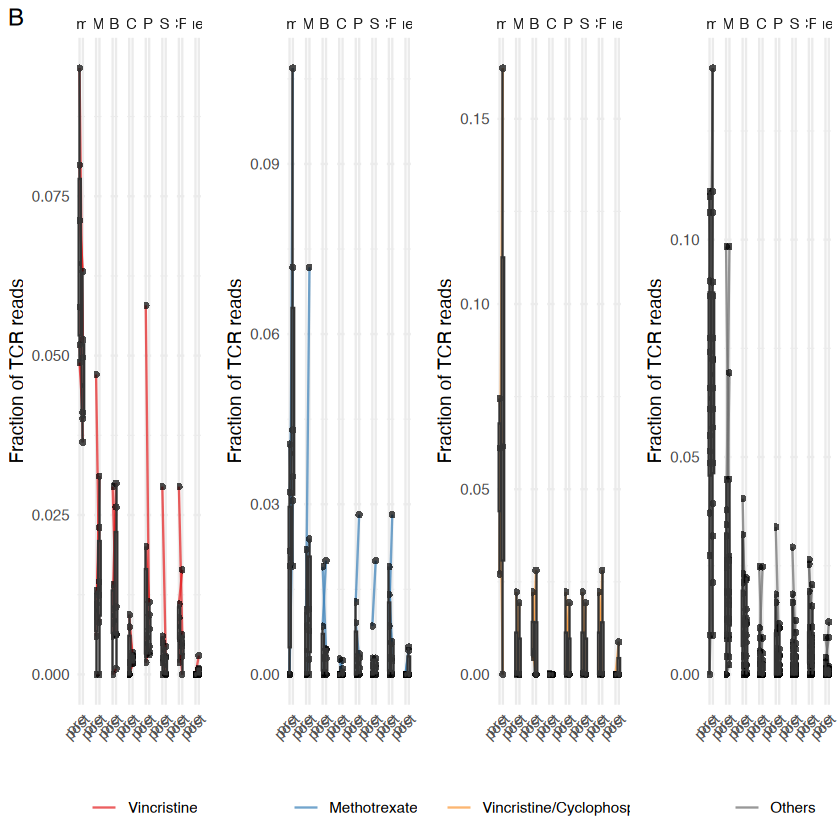

In [105]:
combined_boxplots

In [ ]:
# Save to PDF
pdf(paste0(plotpath, "gliph_paired_boxplot_exposed_regimens_antigens.pdf"), width = 17, height = 6)
print(combined_boxplots)
dev.off()

pdf 
  2